In [10]:
import torch
import torch.nn as nn
from lightning.pytorch.utilities.types import OptimizerLRScheduler

from torch.optim import Adam
from torch.distributions.uniform import Uniform
from torch.utils.data import TensorDataset, DataLoader

import lightning as L

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from small_word_predictor import softmax

In [11]:
inputs = torch.tensor([
    [1., 0., 0., 0.],
    [0., 1., 0., 0.],
    [0., 0., 1., 0.],
    [0., 0., 0., 1.],
])

labels = torch.tensor([
    [0., 1., 0., 0.],
    [0., 0., 1., 0.],
    [0., 0., 0., 1.],
    [0., 1., 0., 0.],
])

dataset = TensorDataset(inputs, labels)
dataloader = DataLoader(dataset)

In [12]:
class WordEmbeddingFromScratch(L.LightningModule):

    def __init__(self):
        super().__init__()

        min_value = -0.5
        max_value = 0.5

        self.input1_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input1_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input2_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input2_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input3_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input3_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input4_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input4_w2 = nn.Parameter(Uniform(min_value, max_value).sample())

        self.output1_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output1_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output2_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output2_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output3_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output3_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output4_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output4_w2 = nn.Parameter(Uniform(min_value, max_value).sample())

        self.loss = nn.CrossEntropyLoss()

    def forward(self, input):
        input = input[0]

        inputs_to_top_hidden = (
            (input[0] * self.input1_w1) +
            (input[1] * self.input2_w1) +
            (input[2] * self.input3_w1) +
            (input[3] * self.input4_w1)
        )

        inputs_to_bottom_hidden = (
            (input[0] * self.input1_w2) +
            (input[1] * self.input2_w2) +
            (input[2] * self.input3_w2) +
            (input[3] * self.input4_w2)
        )

        output1 = (
            inputs_to_top_hidden * self.output1_w1
            + inputs_to_bottom_hidden * self.output1_w2
        )
        output2 = (
            inputs_to_top_hidden * self.output2_w1
            + inputs_to_bottom_hidden * self.output2_w2
        )
        output3 = (
            inputs_to_top_hidden * self.output3_w1
            + inputs_to_bottom_hidden * self.output3_w2
        )
        output4 = (
            inputs_to_top_hidden * self.output4_w1
            + inputs_to_bottom_hidden * self.output4_w2
        )

        output_presoftmax = torch.stack([output1, output2, output3, output4])

        return output_presoftmax

    def configure_optimizers(self):
        return Adam(self.parameters(), lr=0.1)

    def training_step(self, batch, bach_idx):
        input_i, label_i = batch
        output_i = self.forward(input_i)
        loss = self.loss(output_i, label_i[0])

        return loss

In [13]:
modelFromScratch = WordEmbeddingFromScratch()

print("Before optimization, the parameters are...")
for name, param in modelFromScratch.named_parameters():
    print(name, param.data)

Before optimization, the parameters are...
input1_w1 tensor(-0.4883)
input1_w2 tensor(-0.2643)
input2_w1 tensor(-0.1463)
input2_w2 tensor(-0.0841)
input3_w1 tensor(-0.0317)
input3_w2 tensor(0.2900)
input4_w1 tensor(0.3141)
input4_w2 tensor(-0.4906)
output1_w1 tensor(-0.2305)
output1_w2 tensor(0.2017)
output2_w1 tensor(-0.3749)
output2_w2 tensor(-0.0908)
output3_w1 tensor(-0.2205)
output3_w2 tensor(-0.3862)
output4_w1 tensor(0.3452)
output4_w2 tensor(-0.1496)


In [15]:
data = {
    "w1": [
        modelFromScratch.input1_w1.item(),
        modelFromScratch.input2_w1.item(),
        modelFromScratch.input3_w1.item(),
        modelFromScratch.input4_w1.item(),
    ],
    "w2": [
        modelFromScratch.input1_w2.item(),
        modelFromScratch.input2_w2.item(),
        modelFromScratch.input3_w2.item(),
        modelFromScratch.input4_w2.item(),
    ],
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,-0.488317,-0.264346,Troll2,input1
1,-0.146277,-0.084145,is,input2
2,-0.031687,0.290039,great,input3
3,0.314074,-0.490607,Gymkata,input4


Text(0.3140735626220703, -0.4906071424484253, 'Gymkata')

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


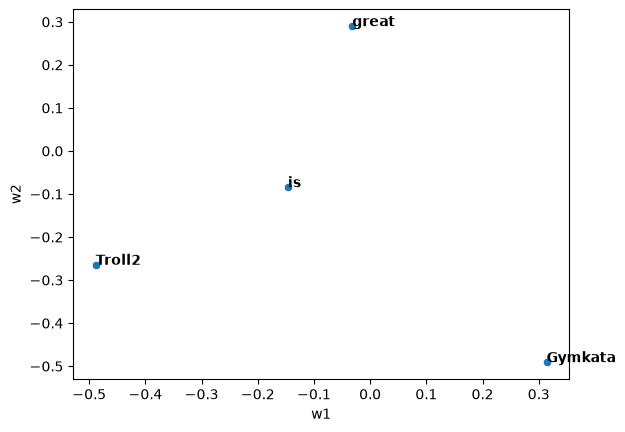

In [17]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [18]:
trainer = L.Trainer(max_epochs=100)
trainer.fit(modelFromScratch, train_dataloaders=dataloader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name         | Type             | Params | Mode  | FLOPs
------------------------------------------------------------------
0 | loss         | CrossEntropyLoss | 0      | train | 0    
  | other params | n/a              | 16     | n/a   | n/a  
------------------------------------------------------------------
16        Trainable params
0         Non-trainable params
16        Total params
0.000     Total estimated model params size (MB)
1         Modules in train mode
0         

Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 118.84it/s, v_num=17]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 94.78it/s, v_num=17] 


In [19]:
data = {
    "w1": [
        modelFromScratch.input1_w1.item(),
        modelFromScratch.input2_w1.item(),
        modelFromScratch.input3_w1.item(),
        modelFromScratch.input4_w1.item(),
    ],
    "w2": [
        modelFromScratch.input1_w2.item(),
        modelFromScratch.input2_w2.item(),
        modelFromScratch.input3_w2.item(),
        modelFromScratch.input4_w2.item(),
    ],
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,-2.359201,-1.462269,Troll2,input1
1,2.186738,-2.506843,is,input2
2,1.611090,2.307295,great,input3
3,-1.891225,-2.169277,Gymkata,input4


Text(-1.8912254571914673, -2.169276714324951, 'Gymkata')

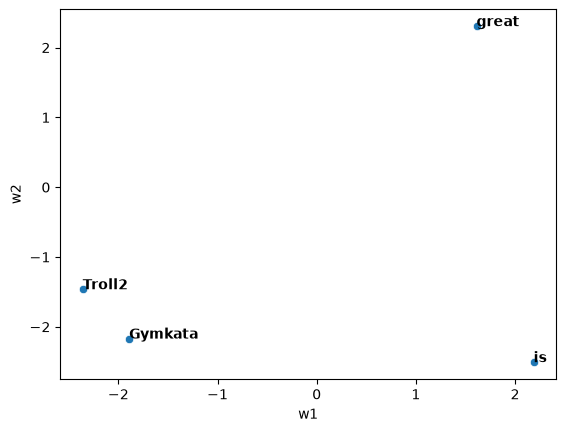

In [20]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [22]:
softmax = nn.Softmax(dim=0)
print(torch.round(softmax(modelFromScratch(torch.tensor([[1., 0., 0., 0,]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 1., 0., 0,]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 0., 1., 0,]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 0., 0., 1.]])))))

tensor([0., 1., 0., 0.], grad_fn=<RoundBackward0>)
tensor([0., 0., 1., 0.], grad_fn=<RoundBackward0>)
tensor([0., 0., 0., 1.], grad_fn=<RoundBackward0>)
tensor([0., 1., 0., 0.], grad_fn=<RoundBackward0>)


In [23]:
class WordEmbeddingWithLinear(L.LightningModule):
    def __init__(self):
        super().__init__()

        self.input_to_hidden = nn.Linear(in_features=4, out_features=2, bias=False)
        self.hidden_to_output = nn.Linear(in_features=2, out_features=4, bias=False)

        self.loss = nn.CrossEntropyLoss()

    def forward(self, input):

        hidden = self.input_to_hidden(input)
        output_values = self.hidden_to_output(hidden)
        return output_values

    def configure_optimizers(self):
        return Adam(self.parameters(), lr=0.1)

    def training_step(self, batch, bach_idx):
        input_i, label_i = batch
        output_i = self.forward(input_i)
        loss = self.loss(output_i, label_i[0])

        return loss

In [24]:
modelLinear = WordEmbeddingWithLinear()

data = {
    "w1": modelLinear.input_to_hidden.weight.detach()[0].numpy(),
    "w2": modelLinear.input_to_hidden.weight.detach()[1].numpy(),
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,0.202277,-0.165277,Troll2,input1
1,-0.082771,0.305653,is,input2
2,0.093068,-0.136532,great,input3
3,0.290446,-0.442676,Gymkata,input4


Text(0.2904459238052368, -0.44267594814300537, 'Gymkata')

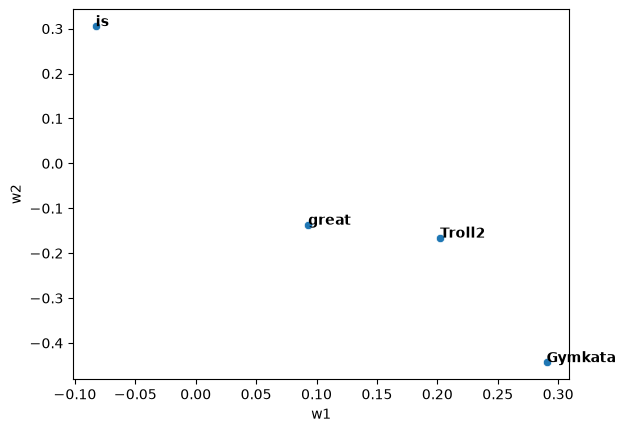

In [26]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [27]:
trainer = L.Trainer(max_epochs=100)
trainer.fit(modelFromScratch, train_dataloaders=dataloader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name         | Type             | Params | Mode  | FLOPs
------------------------------------------------------------------
0 | loss         | CrossEntropyLoss | 0      | train | 0    
  | other params | n/a              | 16     | n/a   | n/a  
------------------------------------------------------------------
16        Trainable params
0         Non-trainable params
16        Total params
0.000     Total estimated model params size (MB)
1         Modules in train mode
0         

Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 169.83it/s, v_num=18]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 128.26it/s, v_num=18]
